# معيار — دفتر التحليل

يشغّل هذا الدفتر التحليل كاملًا من ملفات المستودع، ويعرض النتائج التي يعتمد عليها الملخص التنفيذي (`report/executive_summary.pdf`).

**المدخلات:**
- `data_raw/Charities_-_Dashboard_2.csv`: بيانات الجهات غير الربحية (منصة البيانات المفتوحة).
- `data_clean/legal_articles_full.csv`: مواد اللائحة التنفيذية (129) وقواعد الحوكمة (47) بعد التنظيف، وهو ناتج `notebooks/01_clean_legal_articles.ipynb`.
- `outputs/نتائج_النموذج.xlsx`: نتائج نموذج المطابقة وتقييمه البشري، من `notebooks/02_model_matching.ipynb`.

**التشغيل:** من جذر المستودع (`pip install -r requirements.txt`)، ثم Run All. المدة أقل من دقيقة.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display
from run_pipeline import main
main()   # يكتب الجداول في outputs/ والرسوم في outputs/figures/
OUT, FIG = ROOT / 'outputs', ROOT / 'outputs' / 'figures'
m = json.loads((OUT / 'run_metrics.json').read_text(encoding='utf-8'))

ok [('منطقة الرياض', 798), ('منطقة مكة المكرمة', 444)] ['جمعية أهلية', 'مؤسسة أهلية'] [2450, 273]
{
  "charities": {
    "rows": 2723,
    "entity_counts": {
      "جمعية أهلية": 2450,
      "مؤسسة أهلية": 273
    },
    "top_regions": {
      "الرياض": 798,
      "مكة المكرمة": 444,
      "القصيم": 227
    },
    "reg_number_shared_rows": 516,
    "reg_number_unique_values": 2465,
    "truncated_names": 292,
    "exact_duplicate_group_rows": 44,
    "governance_score_columns": 0,
    "governance_score_analysis": "لم يُنفَّذ: الملف لا يحتوي على درجات حوكمة، ولا يوجد ملف درجات منفصل.",
    "hhi": 1458,
    "hhi_min_equal": 769,
    "top3_regions_pct": 53.9,
    "region_type_cramers_v": 0.26,
    "regions_with_foundations": 8,
    "foundations_in_riyadh": 164
  },
  "legal": {
    "source": "data_clean/legal_articles_full.csv",
    "sequence_checks": {
      "reg": {
        "found": 129,
        "expected": 129
      },
      "gov": {
        "found": 47,
        "expected": 47
      }


## 1. الجهات غير الربحية: الجودة والتوزيع

,check,value,note,share_pct
0,إجمالي السجلات,2723,لا يُحذف أي سجل,NaN
1,عناوين الأعمدة مطابقة للمتوقع,4,"رقم التسجيل, اسم الجمعية, نوع الجهة, المنطقة",NaN
2,سجلات مكررة تماماً (الاسم والنوع والمنطقة),44,تُعرض ولا تُحذف؛ قد تكون جهات مختلفة بأسماء مت...,1.62
3,سجلات يشترك رقم تسجيلها مع سجل آخر,516,رقم التسجيل غير فريد؛ لا يصلح مفتاحاً للربط,18.95
4,أرقام تسجيل غير رقمية,0,التحقق من الشكل فقط,0.00
5,أسماء مقطوعة (تنتهي بـ …),292,القطع من المصدر؛ لا يمكن استرجاع الاسم الكامل,10.72


,entity_type,total,share_pct
0,جمعية أهلية,2450,89.97
1,مؤسسة أهلية,273,10.03


,region,total,associations,foundations,share_pct
0,الرياض,798,634,164,29.31
1,مكة المكرمة,444,395,49,16.31
2,القصيم,227,214,13,8.34
3,المنطقة الشرقية,223,196,27,8.19
4,عسير,220,211,9,8.08
5,المدينة المنورة,183,177,6,6.72
6,جازان,148,148,0,5.44
7,حائل,130,130,0,4.77
8,الباحة,90,90,0,3.31
9,تبوك,73,73,0,2.68


مؤشر التركز HHI = 1,458 (الحد الأدنى لو توزعت بالتساوي 769)، حصة أعلى ثلاث مناطق 53.9%، كرامر V بين النوع والمنطقة = 0.26، مناطق فيها مؤسسات 8، مؤسسات الرياض 164


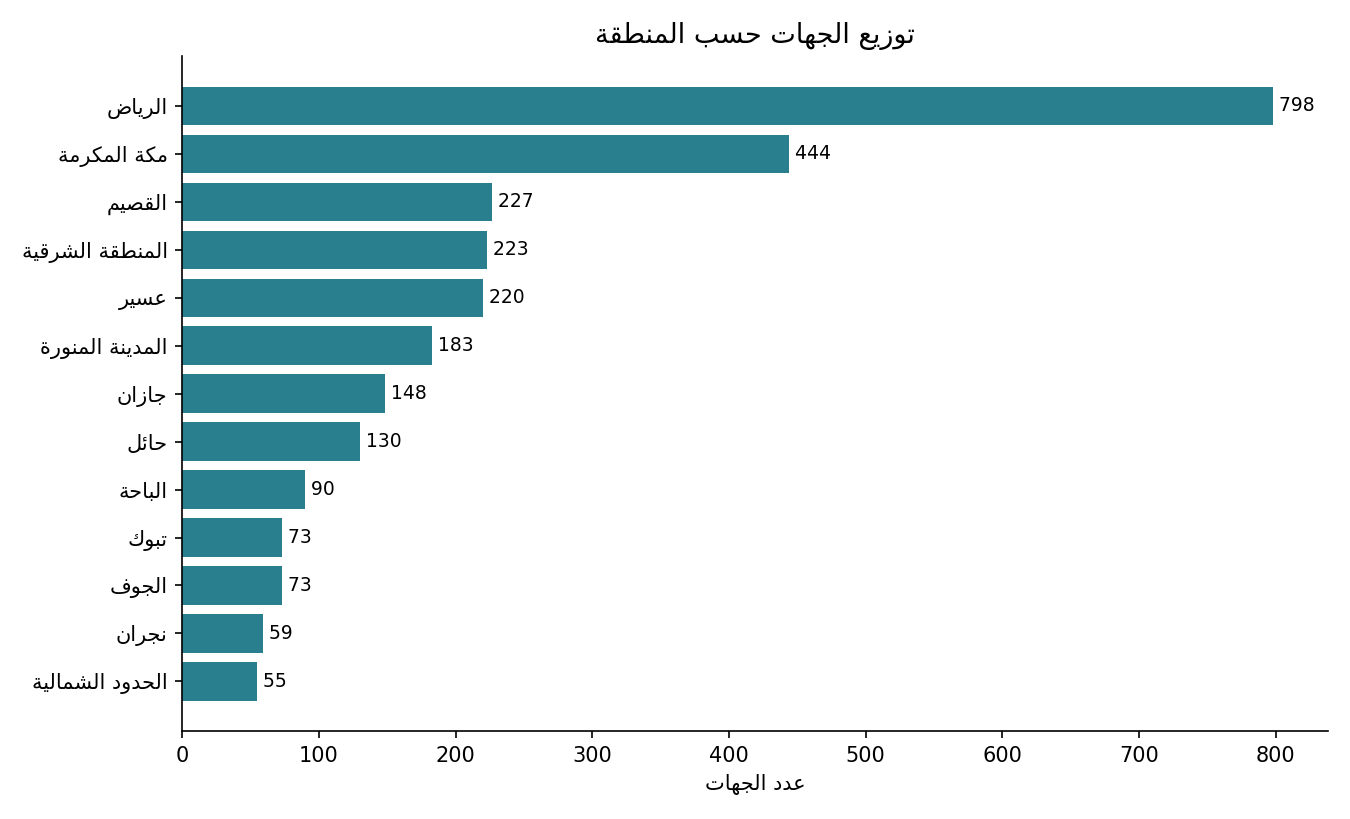

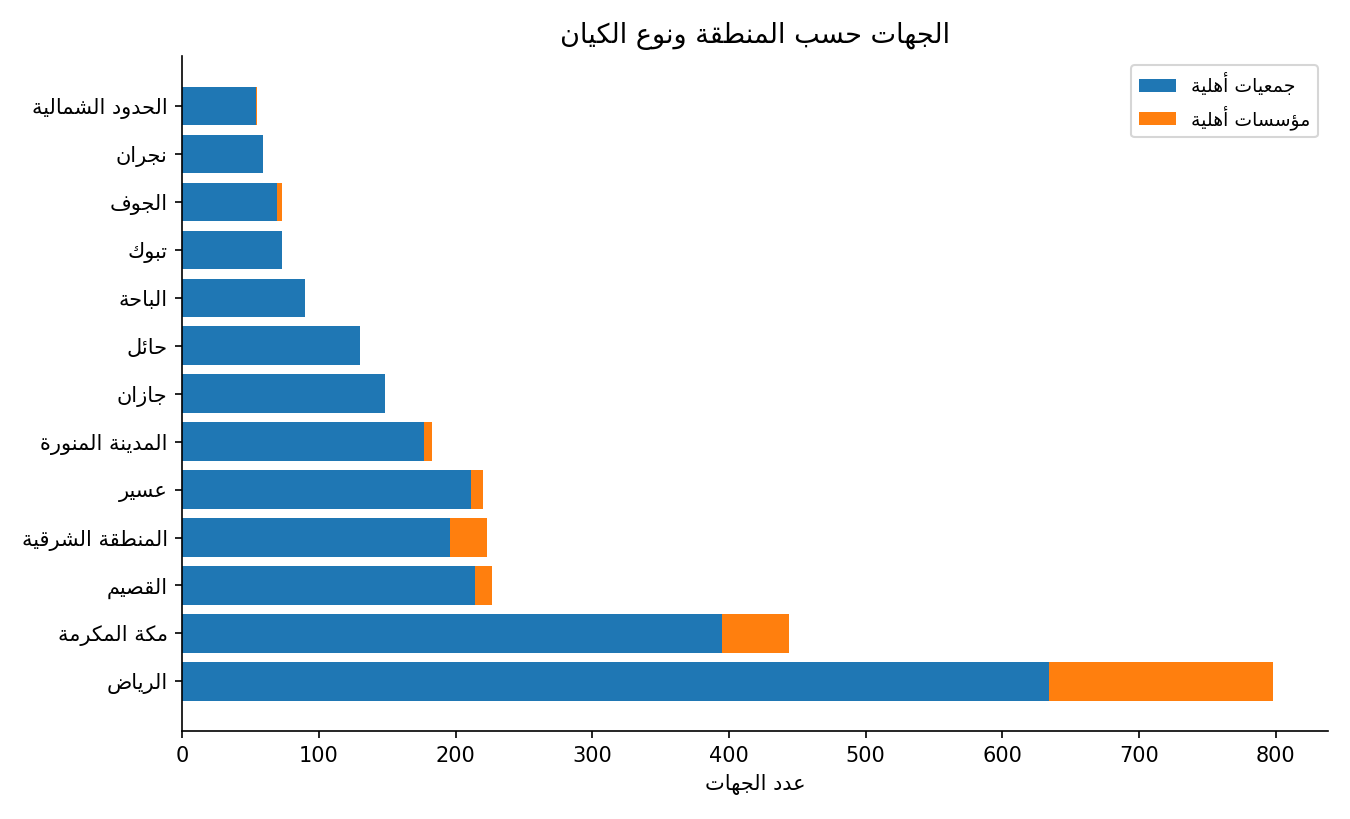

In [2]:
display(pd.read_csv(OUT / 'charities_quality_checks.csv'))
display(pd.read_csv(OUT / 'charities_by_type.csv'))
display(pd.read_csv(OUT / 'charities_by_region.csv'))
c = m['charities']
print(f"مؤشر التركز HHI = {c['hhi']:,} (الحد الأدنى لو توزعت بالتساوي {c['hhi_min_equal']:,})، "
      f"حصة أعلى ثلاث مناطق {c['top3_regions_pct']}%، كرامر V بين النوع والمنطقة = {c['region_type_cramers_v']}، "
      f"مناطق فيها مؤسسات {c['regions_with_foundations']}، مؤسسات الرياض {c['foundations_in_riyadh']}")
for f in ['charities_by_region.png', 'charities_region_by_type.png']:
    display(Image(filename=str(FIG / f)))

## 2. المواد القانونية: الموضوعات في الوثيقتين

المواد 176 (كلها بموضوع: 176)، الموضوعات 25
أكبر موضوع: مجلس الإدارة ومجلس الأمناء = 25 مادة (14.2%)، أكبر موضوعين 25.0%
11 موضوعًا تغطي 83.0% من المواد
مربع كاي = 98.2، درجات الحرية 24، p = 6.0e-11، كرامر V = 0.75 (خلايا تكرارها المتوقع أقل من 5: 76%)
اختلاف التصنيفين الآليين: 79 مادة، منها 45 بلا تعديل موثق؛ مواد معدّلة الموضوع بسبب موثق: 49


,topic,gov_articles,reg_articles,total_articles,gov_share_pct,reg_share_pct
0,مجلس الإدارة ومجلس الأمناء,1,24,25,2.1,18.6
1,التأسيس والترخيص والتسجيل,0,19,19,0.0,14.7
2,الانتخابات والترشح,11,5,16,23.4,3.9
3,العضوية,6,8,14,12.8,6.2
4,الحل والدمج,0,13,13,0.0,10.1
5,اللجان,10,3,13,21.3,2.3
6,المجالس الوطنية والفرعية,0,12,12,0.0,9.3
7,المالية والموارد,0,11,11,0.0,8.5
8,أحكام عامة وختامية,4,6,10,8.5,4.7
9,الجمعية العمومية,1,6,7,2.1,4.7


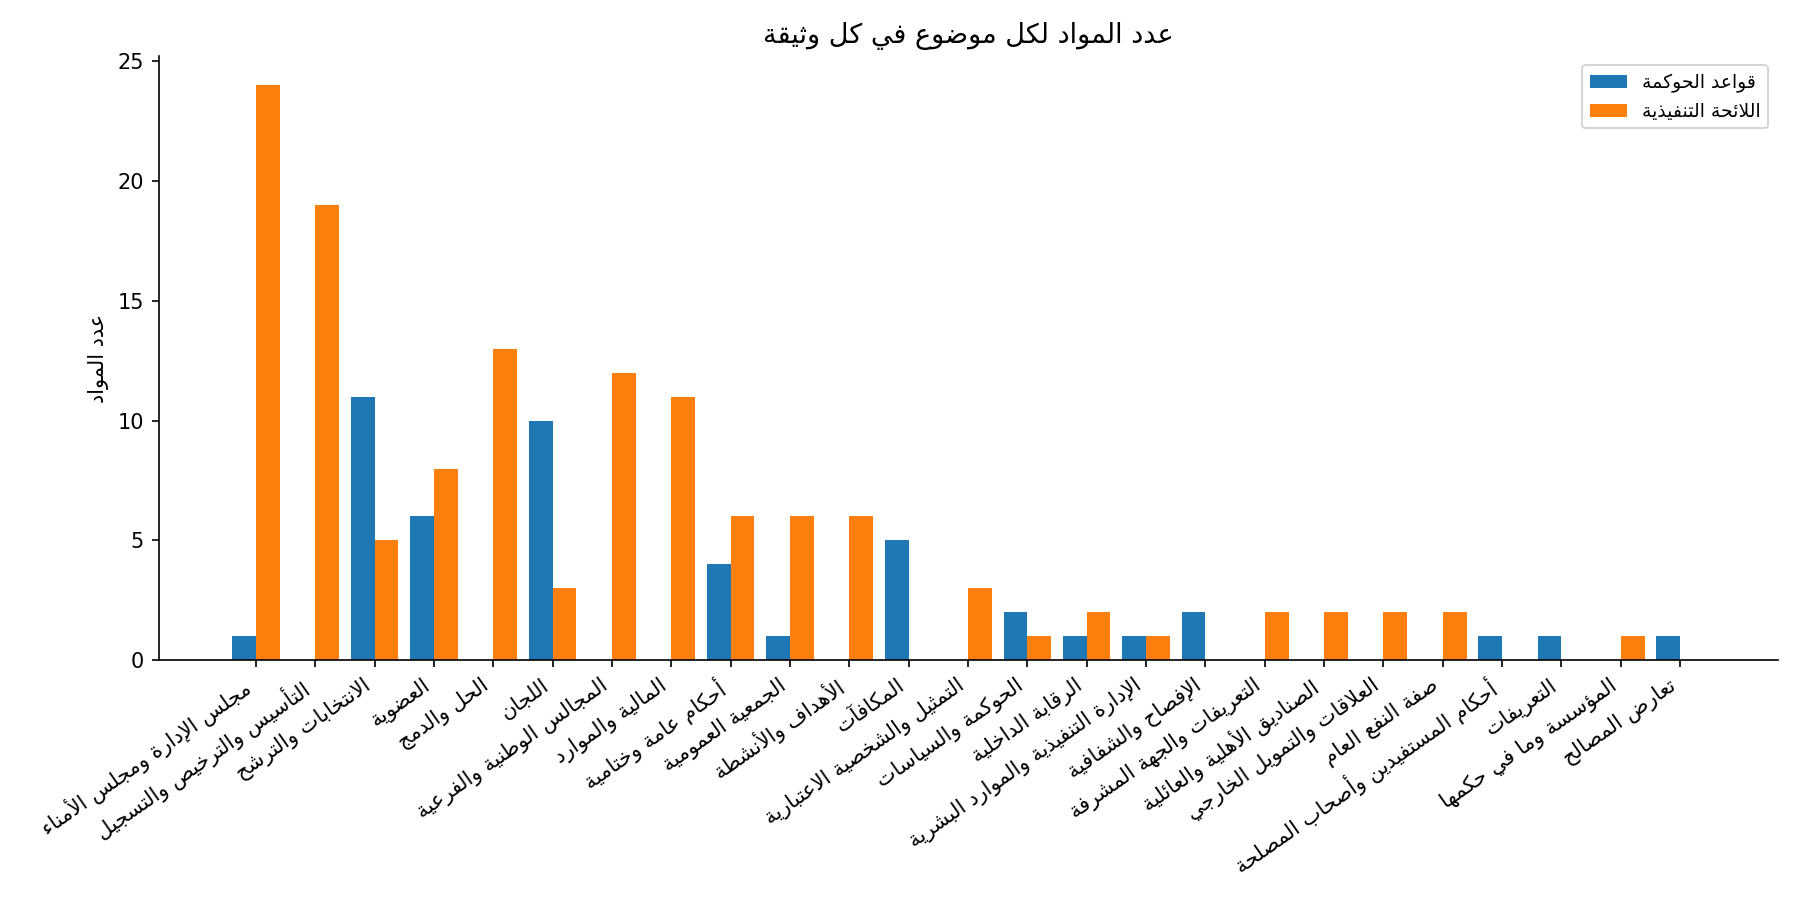

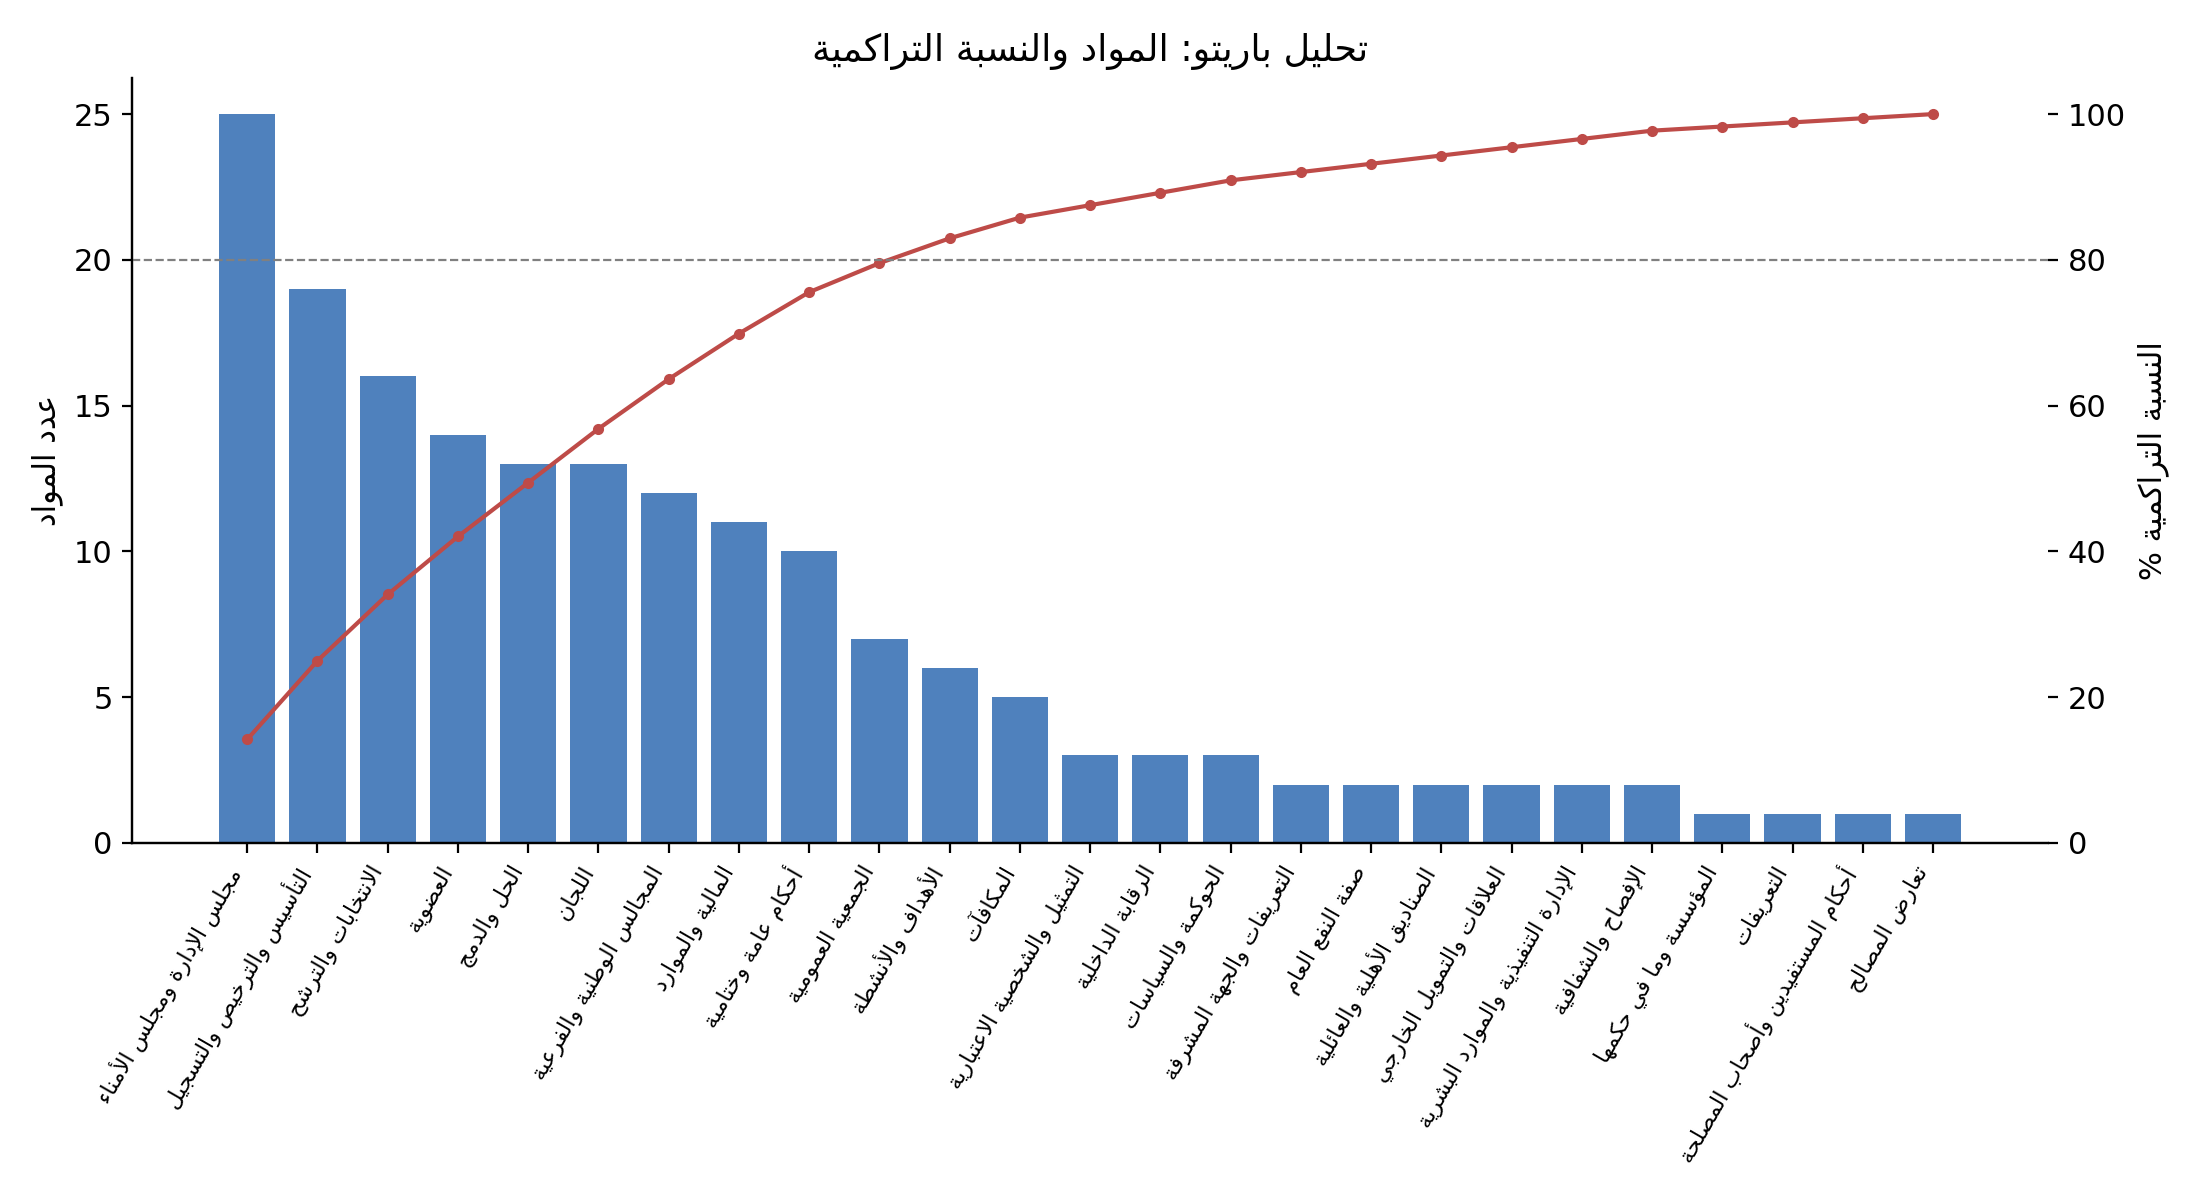

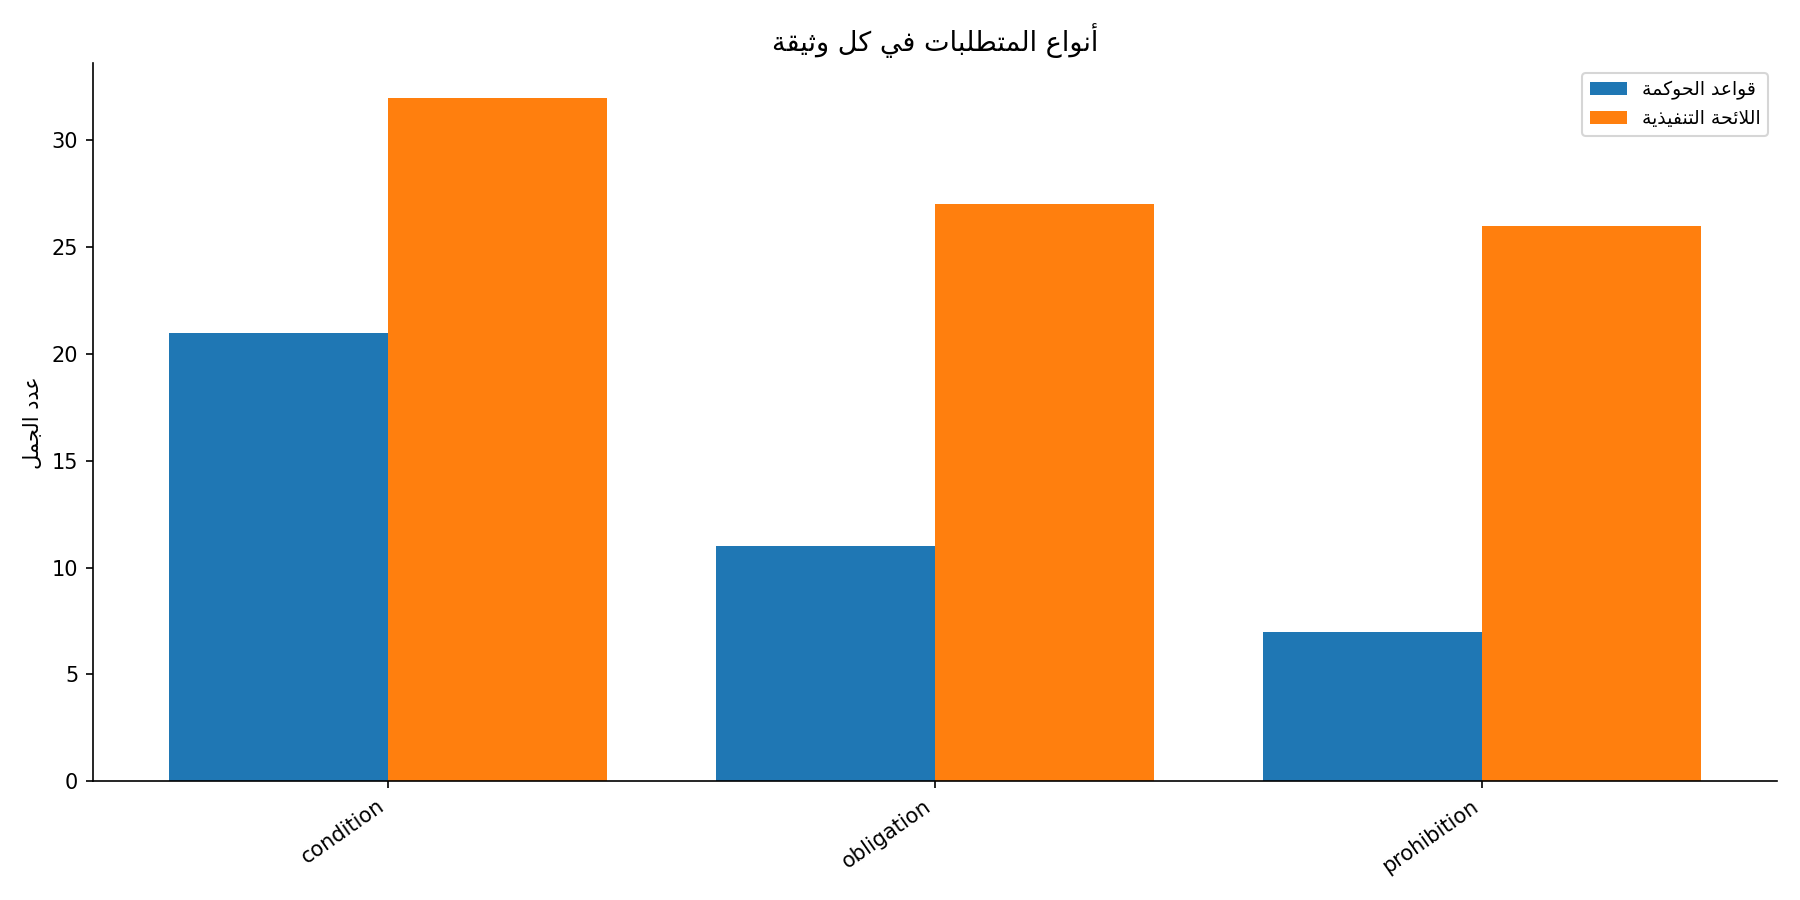

In [3]:
t = m['legal']['topic_stats']
print(f"المواد {m['legal']['articles_total']} (كلها بموضوع: {m['legal']['articles_with_primary_topic']})، الموضوعات {t['topics']}")
print(f"أكبر موضوع: {t['largest_topic']} = {t['largest_topic_articles']} مادة ({t['largest_topic_pct']}%)، أكبر موضوعين {t['top2_pct']}%")
print(f"{t['pareto_topics_for_80pct']} موضوعًا تغطي {t['pareto_cover_pct']}% من المواد")
print(f"مربع كاي = {t['chi2']}، درجات الحرية {t['chi2_dof']}، p = {t['chi2_p']:.1e}، كرامر V = {t['cramers_v']} "
      f"(خلايا تكرارها المتوقع أقل من 5: {t['chi2_cells_expected_below_5_pct']:.0f}%)")
print(f"اختلاف التصنيفين الآليين: {t['rule_vs_tfidf_disagree']} مادة، منها {t['rule_vs_tfidf_disagree_without_documented_override']} "
      f"بلا تعديل موثق؛ مواد معدّلة الموضوع بسبب موثق: {t['articles_with_documented_override']}")
display(pd.read_csv(OUT / 'topic_counts_by_document.csv'))
for f in ['legal_topics_by_document.png', '05_topics_pareto.png', 'legal_requirement_types.png']:
    display(Image(filename=str(FIG / f)))

## 3. نموذج مطابقة قواعد الحوكمة باللائحة التنفيذية

النتائج من `notebooks/02_model_matching.ipynb` والمراجعة البشرية، كما هي في `outputs/نتائج_النموذج.xlsx`.

In [4]:
summary = pd.read_excel(OUT / 'نتائج_النموذج.xlsx', sheet_name='الملخص')
with pd.option_context('display.max_colwidth', None):
    display(summary)
display(pd.read_excel(OUT / 'نتائج_النموذج.xlsx', sheet_name='الدقة').dropna(how='all').head(8))

,البند,النتيجة
0,الطريقة المعتمدة,BAAI/bge-m3 (خط الأساس: TF-IDF)
1,المهمة,لكل مادة من قواعد الحوكمة (47): أقرب 3 مواد في المعنى من اللائحة التنفيذية (129)
2,الدقة المرنة — bge-m3 (كل المواد),41 من 47 = 87% [مدى الثقة 95%: 75%–94%] — بين المقترحات الثلاثة مادة مطابقة أو مطابقة جزئيًا
3,الدقة المرنة — TF-IDF (كل المواد),40 من 47 = 85% [72%–93%]
4,الدقة الصارمة — الطريقتان,23 من 47 = 49% [35%–63%] — بين المقترحات الثلاثة مادة مطابقة تمامًا
5,الفرق بين الطريقتين,غير مثبت؛ اعتُمد bge-m3 لأنه يقرأ المادة كاملة
6,حد التشابه المعتمد,0.75 (أعلى Youden's J): فوقه 43 مقترحًا، 91% منها صحيح (15 مطابق، 24 جزئية، 4 غير مطابق)
7,مواد حوكمة لها مقترح فوق الحد,21 من 47
8,مواد حوكمة بلا مقابل بين المقترحات الستة,4: الحوكمة م14، 25، 32، 40 (لا يعني وحده أن اللائحة لا تغطيها)
9,الاتفاق بين المراجِعات,43% من 21 حكمًا، Cohen's kappa = 0.13 (ضعيف)


,النطاق,الطريقة,الدقة,مواد صحيحة,من مواد,النسبة,مدى الثقة 95% (من),مدى الثقة 95% (إلى)
0,العينة,TF-IDF,صارمة,11.0,20.0,0.550,0.342,0.742
1,العينة,TF-IDF,مرنة,15.0,20.0,0.750,0.531,0.888
2,العينة,bge-m3,صارمة,11.0,20.0,0.550,0.342,0.742
3,العينة,bge-m3,مرنة,18.0,20.0,0.900,0.699,0.972
4,كل المواد المكتملة,TF-IDF,صارمة,23.0,47.0,0.489,0.353,0.628
5,كل المواد المكتملة,TF-IDF,مرنة,40.0,47.0,0.851,0.723,0.926
6,كل المواد المكتملة,bge-m3,صارمة,23.0,47.0,0.489,0.353,0.628
7,كل المواد المكتملة,bge-m3,مرنة,41.0,47.0,0.872,0.748,0.940


## 4. تحقق: أرقام الملخص التنفيذي

تتوقف الخلية إذا اختلف أي رقم في `report/executive_summary.pdf` عن الناتج.

In [5]:
report = {'الكيانات': (c['rows'], 2723), 'أعلى ثلاث مناطق %': (c['top3_regions_pct'], 53.9), 'HHI': (c['hhi'], 1458),
          'الحد الأدنى HHI': (c['hhi_min_equal'], 769), 'V النوع والمنطقة': (c['region_type_cramers_v'], 0.26),
          'المواد': (m['legal']['articles_total'], 176), 'الموضوعات': (t['topics'], 25),
          'أكبر موضوع': (t['largest_topic_articles'], 25), 'أكبر موضوع %': (t['largest_topic_pct'], 14.2),
          'أكبر موضوعين %': (t['top2_pct'], 25.0), 'موضوعات 80%': (t['pareto_topics_for_80pct'], 11),
          'تغطيتها %': (t['pareto_cover_pct'], 83.0), 'مربع كاي': (t['chi2'], 98.2), 'كرامر V': (t['cramers_v'], 0.75),
          'خلايا <5 %': (t['chi2_cells_expected_below_5_pct'], 76), 'اختلاف التصنيفين': (t['rule_vs_tfidf_disagree'], 79),
          'بلا تعديل موثق': (t['rule_vs_tfidf_disagree_without_documented_override'], 45),
          'معدّلة الموضوع': (t['articles_with_documented_override'], 49)}
acc = pd.read_excel(OUT / 'نتائج_النموذج.xlsx', sheet_name='الدقة').dropna(subset=['الطريقة'])
acc = acc[acc['النطاق'] == 'كل المواد المكتملة'].set_index(['الطريقة', 'الدقة'])['مواد صحيحة']
mt = pd.read_csv(OUT / 'المطابقات_النهائية_bge_m3.csv', encoding='utf-8-sig')
above = mt[mt['فوق الحد 0.75']]
nm = pd.read_excel(OUT / 'نتائج_النموذج.xlsx', sheet_name='بلا مقابل بين المقترحات')
nomatch = sorted(int(v) for v in pd.to_numeric(nm['مادة الحوكمة'], errors='coerce').dropna())
report.update({'bge-m3 مرنة': (int(acc[('bge-m3', 'مرنة')]), 41), 'TF-IDF مرنة': (int(acc[('TF-IDF', 'مرنة')]), 40),
               'bge-m3 صارمة': (int(acc[('bge-m3', 'صارمة')]), 23), 'TF-IDF صارمة': (int(acc[('TF-IDF', 'صارمة')]), 23),
               'مقترحات فوق 0.75': (len(above), 43), 'منها صحيحة': (int(above['الحكم المعتمد'].isin(['مطابق', 'مطابقة جزئية']).sum()), 39),
               'مواد لها مقترح فوق الحد': (above['مادة الحوكمة'].nunique(), 21)})
report['بلا مقابل بين المقترحات الستة'] = (nomatch, [14, 25, 32, 40])
ag = pd.read_excel(OUT / 'نتائج_النموذج.xlsx', sheet_name='الاتفاق', header=None)
cl = pd.read_excel(OUT / 'نتائج_النموذج.xlsx', sheet_name='التجميع - الملخص', header=None).set_index(0)[1]
report.update({'أحكام الاتفاق': (int(ag.iat[0, 1]), 21), 'نسبة الاتفاق %': (round(100 * ag.iat[0, 3]), 43),
               "Cohen's kappa": (round(ag.iat[0, 5], 2), 0.13), 'وحدات التجميع': (int(cl['الوحدات (التوائم وحدة واحدة)']), 150),
               'k': (int(cl['k المختار (أعلى silhouette)']), 29), 'silhouette': (round(float(cl['silhouette عند k']), 3), 0.147),
               'ARI': (round(float(cl['ARI مع primary_topic']), 2), 0.28)})
check = pd.DataFrame([(k, str(a), str(b), a == b) for k, (a, b) in report.items()], columns=['البند', 'الناتج', 'في الملخص', 'مطابق'])
display(check)
assert check['مطابق'].all(), check[~check['مطابق']]
print('كل أرقام الملخص التنفيذي مطابقة للناتج.')

,البند,الناتج,في الملخص,مطابق
0,الكيانات,2723,2723,True
1,أعلى ثلاث مناطق %,53.9,53.9,True
2,HHI,1458,1458,True
3,الحد الأدنى HHI,769,769,True
4,V النوع والمنطقة,0.26,0.26,True
5,المواد,176,176,True
6,الموضوعات,25,25,True
7,أكبر موضوع,25,25,True
8,أكبر موضوع %,14.2,14.2,True
9,أكبر موضوعين %,25.0,25.0,True


كل أرقام الملخص التنفيذي مطابقة للناتج.
